# Chapter 9 — 데이터 전처리와 Feature 생성 (실습)

## 실습 목표
1. inf/NaN 처리 (replace + KNNImputer)
2. RobustScaler 정규화
3. 명목형 One-Hot 인코딩
4. 시간·도메인 파생 feature 5개 생성
5. sklearn Pipeline 으로 묶기

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q matplotlib
# !pip install -q scikit-learn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

rng = np.random.default_rng(42)

In [4]:
# 데이터 준비 (ch08 와 유사한 mock)
def make_rows(n, label, dur, pkts, syn, ports):
    return pd.DataFrame({
        'Source IP': rng.choice([f'10.0.0.{i}' for i in range(1,50)], size=n),
        'Destination Port': rng.choice(ports, size=n),
        'Flow Duration': rng.uniform(*dur, size=n),
        'Total Fwd Packets': rng.integers(*pkts, size=n),
        'Total Backward Packets': rng.integers(0, 10, size=n) if label != 'BENIGN' else rng.integers(*pkts, size=n),
        'Total Length of Fwd Packets': rng.integers(*pkts, size=n) * rng.integers(60, 1500, size=n),
        'SYN Flag Count': rng.uniform(*syn, size=n),
        'ACK Flag Count': rng.uniform(0.0 if label != 'BENIGN' else 0.4, 0.6, size=n),
        'Protocol': rng.choice(['TCP', 'UDP'], size=n, p=[0.85, 0.15]),
        'Timestamp': pd.to_datetime('2024-07-05') + pd.to_timedelta(rng.integers(0, 86400, size=n), unit='s'),
        'Label': label,
    })

df = pd.concat([
    make_rows(16000, 'BENIGN',   (1000, 1_000_000), (5, 100),    (0, 0.05),  [80, 443, 53, 22]),
    make_rows( 2300, 'DDoS',     (10, 5000),         (500, 5000), (0.4, 0.7), [80, 443]),
    make_rows( 1200, 'PortScan', (1, 200),           (1, 5),      (0.85, 1.0), list(range(1, 1024))),
], ignore_index=True).sample(frac=1, random_state=0).reset_index(drop=True)

# inf 시뮬레이션
df['Flow Bytes/s'] = np.where(df['Flow Duration'] < 0.001, np.inf, df['Total Length of Fwd Packets'] / df['Flow Duration'].clip(lower=1e-6))
# 결측 시뮬레이션 (Flow Duration 의 1% 를 NaN)
mask = rng.random(len(df)) < 0.01
df.loc[mask, 'Flow Duration'] = np.nan
print(f'shape: {df.shape}')
df.head()

shape: (19500, 12)


,Source IP,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,SYN Flag Count,ACK Flag Count,Protocol,Timestamp,Label,Flow Bytes/s
0,10.0.0.35,80,48068.615060,77,27,12264,0.014924,0.558941,TCP,2024-07-05 04:01:15,BENIGN,0.255135
1,10.0.0.28,53,961721.752453,30,41,54492,0.036182,0.534194,TCP,2024-07-05 17:44:41,BENIGN,0.056661
2,10.0.0.10,443,446554.504113,10,22,45030,0.012332,0.579213,UDP,2024-07-05 03:24:52,BENIGN,0.100839
3,10.0.0.16,148,24.315196,3,7,171,0.956809,0.496242,TCP,2024-07-05 02:35:37,PortScan,7.032639
4,10.0.0.3,443,4818.423548,1771,8,1100400,0.698577,0.593583,TCP,2024-07-05 01:40:11,DDoS,228.373448


---
## Step 1. inf/NaN 처리

In [5]:
# 1) inf → NaN
df = df.replace([np.inf, -np.inf], np.nan)
miss_pct = df.isna().mean().mul(100).round(2)
print('--- 결측 비율 ---')
print(miss_pct[miss_pct > 0])

# 2) 먼저 분할하고 학습 행에서만 대치기 학습
from sklearn.model_selection import train_test_split
train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=df["Label"], random_state=42)
num_cols = ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
            'Total Length of Fwd Packets', 'SYN Flag Count', 'ACK Flag Count', 'Flow Bytes/s']
imp = KNNImputer(n_neighbors=5)
imp.fit(df.loc[train_idx, num_cols])
df[num_cols] = imp.transform(df[num_cols])
print(f'\n처리 후 결측: {df[num_cols].isna().sum().sum()}')

--- 결측 비율 ---
Flow Duration    1.0
dtype: float64

처리 후 결측: 0


---
## Step 2. 이상치 — clipping + log

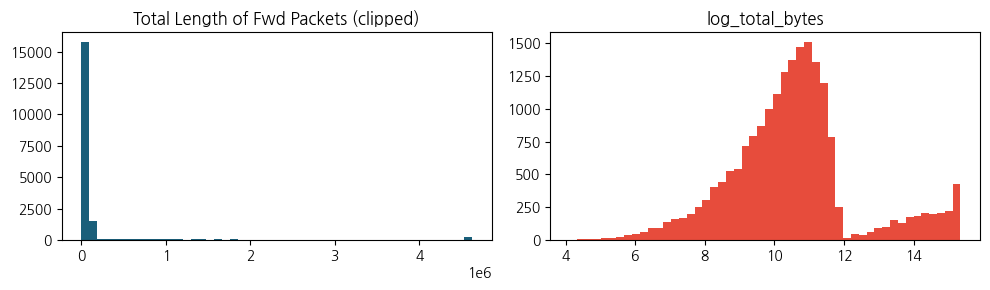

In [6]:
# Winsorize 99 percentile
for col in ['Flow Bytes/s', 'Total Length of Fwd Packets']:
    upper = df.loc[train_idx, col].quantile(0.99)
    df[col] = df[col].clip(upper=upper)

# log 변환 — 우측 치우친 분포
df['log_total_bytes'] = np.log1p(df['Total Length of Fwd Packets'])
df['log_flow_dur'] = np.log1p(df['Flow Duration'])

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(df['Total Length of Fwd Packets'], bins=50, color='#1a5f7a')
axes[0].set_title('Total Length of Fwd Packets (clipped)')
axes[1].hist(df['log_total_bytes'], bins=50, color='#e74c3c')
axes[1].set_title('log_total_bytes')
plt.tight_layout(); plt.show()

---
## Step 3. 인코딩 — One-Hot + 라벨 인코딩

In [7]:
# Protocol One-Hot
df = pd.get_dummies(df, columns=['Protocol'], prefix='proto')

# 라벨 인코딩 — 이진 + 다중
df['label_bin'] = (df['Label'] != 'BENIGN').astype(int)
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['Label'])
print('라벨 매핑:', dict(zip(le.classes_, range(len(le.classes_)))))
df[['Label', 'label_bin', 'label_enc', 'proto_TCP', 'proto_UDP']].head()

라벨 매핑: {'BENIGN': 0, 'DDoS': 1, 'PortScan': 2}


,Label,label_bin,label_enc,proto_TCP,proto_UDP
0,BENIGN,0,0,True,False
1,BENIGN,0,0,True,False
2,BENIGN,0,0,False,True
3,PortScan,1,2,True,False
4,DDoS,1,1,True,False


---
## Step 4. 파생 Feature 5개

In [8]:
ts = pd.to_datetime(df['Timestamp'])
df['hour'] = ts.dt.hour
df['is_night'] = ((df['hour'] < 6) | (df['hour'] > 22)).astype(int)
df['bytes_per_pkt'] = df['Total Length of Fwd Packets'] / df['Total Fwd Packets'].clip(lower=1)
df['bwd_to_fwd_ratio'] = df['Total Backward Packets'] / df['Total Fwd Packets'].clip(lower=1)
df['syn_dominance'] = df['SYN Flag Count'] / df['ACK Flag Count'].clip(lower=1e-3)
df['is_well_known_port'] = df['Destination Port'].isin([22, 25, 53, 80, 443, 3389]).astype(int)

# 라벨별 파생 feature 평균 비교
derived = ['is_night', 'bytes_per_pkt', 'bwd_to_fwd_ratio', 'syn_dominance', 'is_well_known_port']
df.groupby('Label')[derived].mean().round(3)

,is_night,bytes_per_pkt,bwd_to_fwd_ratio,syn_dominance,is_well_known_port
Label,,,,,
BENIGN,0.294,1324.140,1.695,0.051,1.000
DDoS,0.290,1051.611,0.002,6.435,1.000
PortScan,0.288,994.029,2.464,10.733,0.003


관찰: `syn_dominance` 와 `is_well_known_port` 는 라벨별로 명확히 다르다 → 강한 feature.

---
## Step 5. sklearn Pipeline 으로 통합

In [9]:
from sklearn.model_selection import train_test_split

feature_cols = ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
                'SYN Flag Count', 'ACK Flag Count', 'log_total_bytes',
                'bytes_per_pkt', 'bwd_to_fwd_ratio', 'syn_dominance',
                'is_night', 'is_well_known_port', 'proto_TCP', 'proto_UDP']
X = df[feature_cols]
y = df['label_bin']

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

pipe = Pipeline([
    ('impute', KNNImputer(n_neighbors=5)),
    ('scale',  RobustScaler()),
])
X_train_proc = pipe.fit_transform(X_train)
X_test_proc  = pipe.transform(X_test)
print(f'X_train_proc.shape = {X_train_proc.shape}')
print(f'평균(첫 3 feature): {X_train_proc[:, :3].mean(axis=0).round(3)}')
print(f'중앙(첫 3 feature): {np.median(X_train_proc[:, :3], axis=0).round(3)}')

X_train_proc.shape = (13650, 13)
평균(첫 3 feature): [0.026 5.447 0.026]
중앙(첫 3 feature): [-0.  0.  0.]


---
## 정리
- KISIA Part 3 의 IRIS 전처리 패턴이 보안 데이터에 그대로 적용된다.
- 보안에서는 RobustScaler + clipping + log 변환이 표준.
- 파생 feature (syn_dominance, is_well_known_port) 가 라벨 구분에 강하다.
- Pipeline 으로 묶으면 fit/transform 일관성을 자동 보장 — leakage 방지.
- 다음 챕터에서 이 전처리 결과로 EDA 와 시각화를 본격 한다.